# Breakfast Cereals Rating Data Preparation with Principal Component Analysis

**Reducing the nutritional variables of 77 breakfast cereals to principal components and preparing training and test sets to model the consumer rating**

**Date:** November 9, 2026

## 1. Business context

Breakfast cereal manufacturers and retailers need to understand which nutritional characteristics are associated with better consumer ratings, both to evaluate existing products and to anticipate how a new product could be rated. The nutritional information of a cereal is described by many variables (calories, protein, fat, sodium, fiber, carbohydrates, sugars, potassium, vitamins and serving size), and some of them move together. With only a few dozen products available, a model that receives all of them as separate inputs has little data to learn from and is prone to overfitting. Reducing the nutritional variables to a smaller set of uncorrelated components with principal component analysis (PCA) is one way to prepare the data for that model.

## 2. Project objective

This project prepares the cereals dataset for modeling the product rating. It covers the following steps:
- assess the structure, completeness and descriptive statistics of the dataset;
- handle the missing values with a documented decision;
- explore how the products are distributed across manufacturers and shelves, and how the rating varies;
- examine how the nutritional variables relate to the rating and to each other;
- split the data into training and test sets before any step that learns from the data, to avoid data leakage;
- scale the numeric predictors and apply PCA, selecting the number of components with a documented criterion;
- interpret the principal components in terms of the original variables;
- select and encode the categorical predictors, with a reason for each decision; and
- produce a training set and a test set that are ready for model training.

The project is data preparation. It does not train a model or estimate its performance.

## 3. Scope and limitations

- The dataset has 77 cereals, 74 after the missing values are removed, which leaves 59 for training and 15 for testing. Every result is sensitive to which cereals fall in each set.
- 73 of the 74 cereals kept are cold cereals, so the findings describe mostly cold cereals.
- The `rating` is a score provided with the data, and its calculation is not documented. The project describes associations with the rating and does not explain what determines it.
- PCA is a linear technique. The components are combinations of the original variables and are harder to read than the variables themselves.
- The project ends at the model-ready datasets.

## 4. Dataset source

The file used for this project is `Cereals.csv`, from the [Cereals datafile](https://dasl.datadescription.com/datafile/cereals/) of the Data and Story Library (DASL), a public collection of statistics datasets. The analysis below is based on this file only. It contains the nutritional information and the shelf location of 77 breakfast cereals. In the original DASL file, the missing nutrient values are coded as -1, and in the file used here they appear as empty values. The file must be saved in the `data` folder before running the notebook.

## 5. Load the data

The CSV file is located in the `data` folder of this project, which makes the analysis easier to reproduce on another computer. The libraries are imported once, in the same cell as the data. The random seed and the share of data reserved for testing are defined here, so the whole notebook is reproducible and easy to adjust. The number of raw rows is stored to report how many rows the cleaning removes.

In [1]:
# Import the libraries used to load, explore, transform, and visualize the data.
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA

# Define the random seed and the share of cereals reserved for testing, so the results are reproducible.
RANDOM_STATE = 42
TEST_SIZE = 0.2

# Load the CSV file into a pandas DataFrame and store the number of raw rows to report what the cleaning removes.
df = pd.read_csv("../data/Cereals.csv")
raw_rows = len(df)

print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

Rows: 77 | Columns: 16


In [2]:
# Define a function that summarizes how many rows a cleaning step removed in a one-row table.
def removal_summary(rows_before, rows_after, label):
    """Summarize the rows before and after a cleaning step in a one-row table."""
    rows_removed = rows_before - rows_after
    percentage_removed = round(rows_removed / rows_before * 100, 2)

    return pd.DataFrame({
        "Rows before": [rows_before],
        "Rows after": [rows_after],
        "Rows removed": [rows_removed],
        "Removed (%)": [percentage_removed]
    }, index=[label])

### Data dictionary

The dataset has 16 columns. The target is `rating`, and the other columns are either candidate predictors or are excluded for the reasons given in section 15.

| Variable | Description | Type | Role |
|---|---|---|---|
| `name` | Name of the cereal | Identifier | Excluded (section 15) |
| `mfr` | Manufacturer: A (American Home Food Products), G (General Mills), K (Kelloggs), N (Nabisco), P (Post), Q (Quaker Oats) or R (Ralston Purina) | Categorical | Predictor |
| `type` | Cold (C) or hot (H) cereal | Categorical | Excluded (section 15) |
| `calories` | Calories per serving | Numeric | Predictor |
| `protein` | Grams of protein per serving | Numeric | Predictor |
| `fat` | Grams of fat per serving | Numeric | Predictor |
| `sodium` | Milligrams of sodium per serving | Numeric | Predictor |
| `fiber` | Grams of dietary fiber per serving | Numeric | Predictor |
| `carbo` | Grams of complex carbohydrates per serving | Numeric | Predictor |
| `sugars` | Grams of sugars per serving | Numeric | Predictor |
| `potass` | Milligrams of potassium per serving | Numeric | Predictor |
| `vitamins` | Vitamins and minerals, as the typical percentage of the amount recommended by the FDA (0, 25 or 100) | Numeric with three levels | Predictor |
| `shelf` | Display shelf (1, 2 or 3, counted from the floor) | Categorical coded as numbers | Predictor |
| `weight` | Weight of one serving, in ounces | Numeric | Predictor |
| `cups` | Number of cups in one serving | Numeric | Predictor |
| `rating` | Rating of the cereal (its calculation is not documented) | Numeric | Target |

## 6. Inspect the dataset structure

The first rows, the data types, the non-null counts and the descriptive statistics show the structure of the dataset and where the missing values are. The numeric variables and the text variables are summarized separately.

In [3]:
# Preview a few records to check the column names and the format of the values.
df.head()

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100%_Bran,N,C,70,4,1,130,10.0,5.0,6.0,280.0,25,3,1.0,0.33,68.402973
1,100%_Natural_Bran,Q,C,120,3,5,15,2.0,8.0,8.0,135.0,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.0,25,3,1.0,0.33,59.425505
3,All-Bran_with_Extra_Fiber,K,C,50,4,0,140,14.0,8.0,0.0,330.0,25,3,1.0,0.50,93.704912
4,Almond_Delight,R,C,110,2,2,200,1.0,14.0,8.0,NaN,25,3,1.0,0.75,34.384843


In [4]:
# Review data types and non-null counts before choosing any transformations.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      77 non-null     str    
 1   mfr       77 non-null     str    
 2   type      77 non-null     str    
 3   calories  77 non-null     int64  
 4   protein   77 non-null     int64  
 5   fat       77 non-null     int64  
 6   sodium    77 non-null     int64  
 7   fiber     77 non-null     float64
 8   carbo     76 non-null     float64
 9   sugars    76 non-null     float64
 10  potass    75 non-null     float64
 11  vitamins  77 non-null     int64  
 12  shelf     77 non-null     int64  
 13  weight    77 non-null     float64
 14  cups      77 non-null     float64
 15  rating    77 non-null     float64
dtypes: float64(7), int64(6), str(3)
memory usage: 9.8 KB


In [5]:
# Summarize the numeric variables with descriptive statistics.
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
calories,77.0,106.88,19.48,50.00,100.00,110.00,110.00,160.0
protein,77.0,2.55,1.09,1.00,2.00,3.00,3.00,6.0
fat,77.0,1.01,1.01,0.00,0.00,1.00,2.00,5.0
sodium,77.0,159.68,83.83,0.00,130.00,180.00,210.00,320.0
fiber,77.0,2.15,2.38,0.00,1.00,2.00,3.00,14.0
carbo,76.0,14.80,3.91,5.00,12.00,14.50,17.00,23.0
sugars,76.0,7.03,4.38,0.00,3.00,7.00,11.00,15.0
potass,75.0,98.67,70.41,15.00,42.50,90.00,120.00,330.0
vitamins,77.0,28.25,22.34,0.00,25.00,25.00,25.00,100.0
shelf,77.0,2.21,0.83,1.00,1.00,2.00,3.00,3.0


In [6]:
# Summarize the text variables with counts, unique values and the most frequent value.
text_vars = df.select_dtypes(include=["object", "string"]).columns
summary = df[text_vars].describe().T
summary = summary.rename(columns={"count": "Count", "unique": "Unique values",
                                  "top": "Most frequent value", "freq": "Frequency"})
summary

,Count,Unique values,Most frequent value,Frequency
name,77,77,100%_Bran,1
mfr,77,7,K,23
type,77,2,C,74


### Initial structure findings

The dataset contains 77 cereals from 7 manufacturers, and 16 columns. Kelloggs (`K`, 23 cereals) and General Mills (`G`, 22) make 45 of the 77 products. 74 cereals are cold and 3 are hot. `carbo` and `sugars` have 76 non-null values and `potass` has 75, and the other columns are complete. The calories go from 50 to 160 per serving, the sodium from 0 to 320 mg and the rating from 18.04 to 93.70, with a mean of 42.67. `shelf` only takes the values 1, 2 and 3, and `vitamins` only 0, 25 and 100, so both are codes for categories or levels and not continuous measurements.

## 7. Assess missing values

The missing values are counted per column, and the cereals that contain them are listed, because only a few rows are affected and the decision depends on which cereals they are.

The rows with missing values are removed, for three reasons. Only a small share of the rows is affected, PCA cannot be applied to incomplete data, and imputing the missing values would mean estimating them from typical cereals. That would be misleading if the affected cereals are not typical. The removal is a decision about whole rows, not a statistic learned from the data, so it is applied before the split without leaking information from the test set.

In [7]:
# Count the missing values in each column.
df.isna().sum()

name        0
mfr         0
type        0
calories    0
protein     0
fat         0
sodium      0
fiber       0
carbo       1
sugars      1
potass      2
vitamins    0
shelf       0
weight      0
cups        0
rating      0
dtype: int64

In [8]:
# List the cereals that have at least one missing value.
cereals_missing_values = df[df.isna().any(axis=1)]
cereals_missing_values

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
4,Almond_Delight,R,C,110,2,2,200,1.0,14.0,8.0,NaN,25,3,1.0,0.75,34.384843
20,Cream_of_Wheat_(Quick),N,H,100,3,0,80,1.0,21.0,0.0,NaN,0,2,1.0,1.00,64.533816
57,Quaker_Oatmeal,Q,H,100,5,2,0,2.7,NaN,NaN,110.0,0,1,1.0,0.67,50.828392


In [9]:
# Remove the rows with missing values and reset the index so it stays consecutive.
df = df.dropna().reset_index(drop=True)
removal_summary(raw_rows, len(df), "Missing Values Removal")

,Rows before,Rows after,Rows removed,Removed (%)
Missing Values Removal,77,74,3,3.9


### Missing value findings

Four values are missing in three cereals: `potass` in Almond Delight and in Cream of Wheat (Quick), and `carbo` and `sugars` in Quaker Oatmeal. Removing these three cereals leaves 74 of the 77 (3.9% removed). Two of the three removed cereals, Cream of Wheat (Quick) and Quaker Oatmeal, are hot cereals, so the removal leaves only one hot cereal in the dataset. This matters for the variable `type` in section 15, and it means the results describe mostly cold cereals.

## 8. Explore manufacturers and shelves

The number of cereals of each manufacturer and on each shelf is counted, and the two variables are combined to see which manufacturers place their products on which shelves. The shelves are counted from the floor, so shelf 1 is the lowest and shelf 3 the highest.

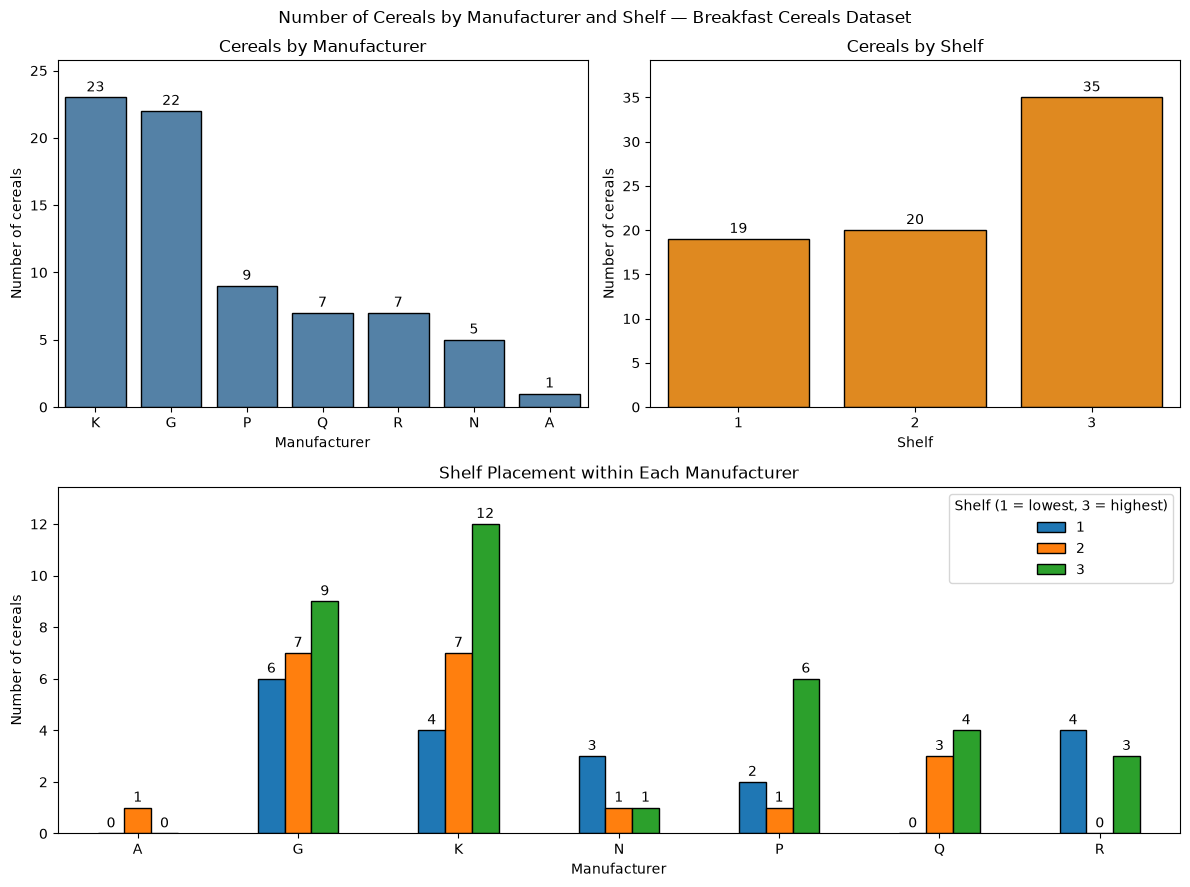

In [10]:
# Count the cereals of each manufacturer and on each shelf.
cereals_by_manufacturer = df["mfr"].value_counts()
cereals_by_shelf = df["shelf"].value_counts().sort_index()

# Combine both variables to count the cereals of each manufacturer on each shelf.
cereals_by_mfr_shelf = pd.crosstab(df["mfr"], df["shelf"], margins=True)

# Version without totals, used only for the grouped bars.
mfr_shelf_counts = pd.crosstab(df["mfr"], df["shelf"])

# Plot three charts: two counts on top and the combination below.
fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

sns.barplot(x=cereals_by_manufacturer.index, y=cereals_by_manufacturer.values,
            ax=ax1, color="steelblue", edgecolor="black")
ax1.bar_label(ax1.containers[0], padding=2)   # number above each bar
ax1.set_title("Cereals by Manufacturer")
ax1.set_xlabel("Manufacturer")
ax1.set_ylabel("Number of cereals")
ax1.tick_params(axis="x", rotation=0)

sns.barplot(x=cereals_by_shelf.index, y=cereals_by_shelf.values,
            ax=ax2, color="darkorange", edgecolor="black")
ax2.bar_label(ax2.containers[0], padding=2)
ax2.set_title("Cereals by Shelf")
ax2.set_xlabel("Shelf")
ax2.set_ylabel("Number of cereals")
ax2.tick_params(axis="x", rotation=0)

mfr_shelf_counts.plot(kind="bar", ax=ax3, edgecolor="black")
for container in ax3.containers:              # one container per shelf
    ax3.bar_label(container, padding=2)
ax3.set_title("Shelf Placement within Each Manufacturer")
ax3.set_xlabel("Manufacturer")
ax3.set_ylabel("Number of cereals")
ax3.tick_params(axis="x", rotation=0)
ax3.legend(title="Shelf (1 = lowest, 3 = highest)")

# Leave some room above the tallest bars so the numbers are not cut off.
for ax in (ax1, ax2, ax3):
    ax.margins(y=0.12)

fig.suptitle("Number of Cereals by Manufacturer and Shelf — Breakfast Cereals Dataset")
plt.tight_layout()
plt.show()

### Manufacturer and shelf findings

Kelloggs (23 cereals, 31.1%) and General Mills (22, 29.7%) make up 60.8% of the 74 cereals, followed by Post (9) and Quaker Oats and Ralston Purina (7 each). Nabisco has 5 cereals and American Home Food Products has a single one, so comparisons that involve these two manufacturers rest on very few cereals. Shelf 3 holds 35 cereals (47.3%), against 20 on shelf 2 and 19 on shelf 1. The manufacturers place their products differently: 12 of the 23 Kelloggs cereals and 6 of the 9 Post cereals are on shelf 3, General Mills is spread across the three shelves (6, 7 and 9), Ralston Purina has no cereal on shelf 2 and Quaker Oats has none on shelf 1.

## 9. Explore the rating

The distribution of the rating, the variable that a future model would predict, is reviewed with descriptive statistics, a table of counts per range of 10 points and a histogram, and the 10 best-rated cereals are listed with their manufacturer.

In [11]:
# Summarize the rating with its descriptive statistics.
df["rating"].describe()

count    74.000000
mean     42.371787
std      14.033712
min      18.042851
25%      32.449210
50%      40.253086
75%      50.520611
max      93.704912
Name: rating, dtype: float64

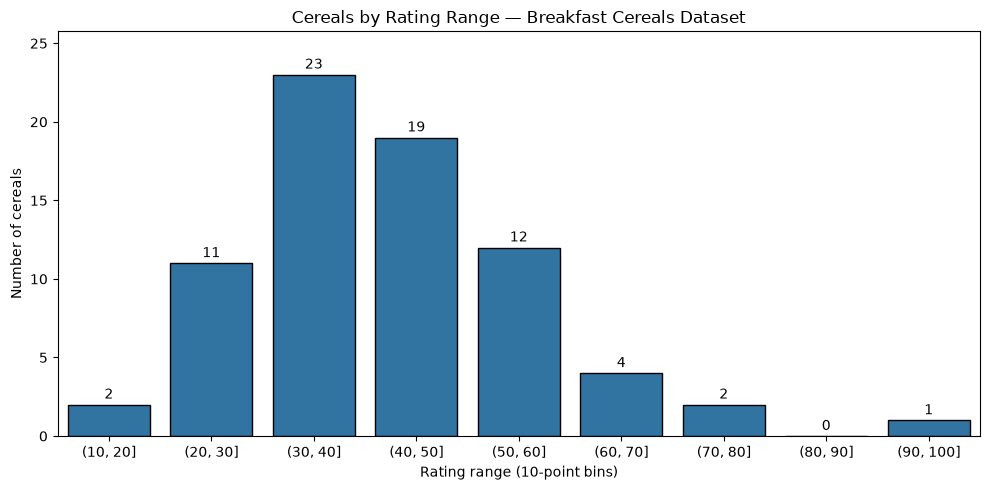

In [12]:
# Count the cereals in each range of 10 rating points.
cereals_by_range = pd.cut(df["rating"], bins=range(10, 101, 10))
cereals_by_range_counts = cereals_by_range.value_counts().sort_index()
cereals_by_range_counts

# Plot the counts. The interval labels are converted to text for the x axis.
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(x=cereals_by_range_counts.index.astype(str), y=cereals_by_range_counts.values,
            ax=ax, edgecolor="black")
ax.bar_label(ax.containers[0], padding=2)   # number above each bar
ax.set_title("Cereals by Rating Range — Breakfast Cereals Dataset")
ax.set_xlabel("Rating range (10-point bins)")
ax.set_ylabel("Number of cereals")
ax.tick_params(axis="x", rotation=0)
ax.margins(y=0.12)

plt.tight_layout()

In [13]:
# List the 10 best-rated cereals and their manufacturer.
best_ratings = df["rating"].sort_values(ascending=False).head(10)
best_cereals = df.loc[best_ratings.index, ["name", "mfr", "rating"]].copy()
best_cereals["rating"] = best_cereals["rating"].map("{:.2f}".format)
best_cereals

,name,mfr,rating
3,All-Bran_with_Extra_Fiber,K,93.70
61,Shredded_Wheat_'n'Bran,N,74.47
62,Shredded_Wheat_spoon_size,N,72.80
0,100%_Bran,N,68.40
60,Shredded_Wheat,N,68.24
53,Puffed_Wheat,Q,63.01
52,Puffed_Rice,Q,60.76
48,Nutri-grain_Wheat,K,59.64
2,All-Bran,K,59.43
65,Strawberry_Fruit_Wheats,N,59.36


### Rating findings

The rating has a mean of 42.37 and a median of 40.25. Most cereals are between 30 and 50 points (23 in the 30 to 40 range and 19 in the 40 to 50 range), and the distribution has a tail towards high values: only 3 cereals are above 70 (two between 70 and 80 and one above 90), and the one above 90 is All-Bran with Extra Fiber (Kelloggs, 93.70). All 5 Nabisco cereals in the dataset are among the 10 best rated, together with 3 Kelloggs and 2 Quaker Oats cereals. The best-rated cereal is far above the others, so it will be an influential point in any model.

## 10. Explore the nutritional variables

The calories of each manufacturer are compared with a boxplot and a table, and the correlation of each numeric variable with the rating is calculated, together with the correlations between the variables themselves. `shelf` is not included in the correlations because it is a category coded with numbers, and it is analyzed in section 15.

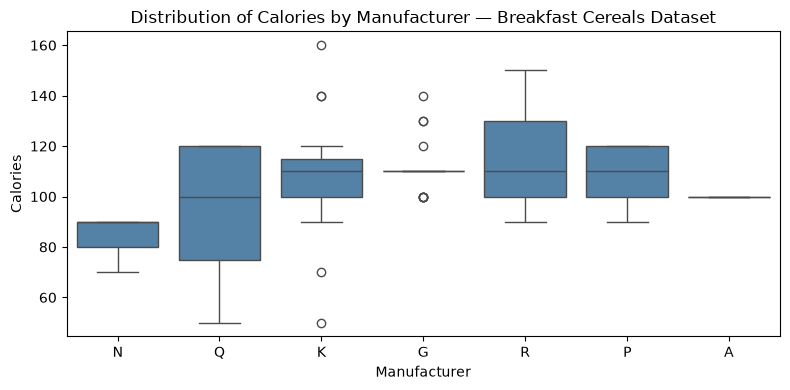

In [14]:
# Plot the calories of each manufacturer with one boxplot per manufacturer.
fig, ax = plt.subplots(figsize=(8, 4))

sns.boxplot(
    data=df,
    x="mfr",
    y="calories",
    color="steelblue",
    ax=ax
)

# Add a title that names the variable and the dataset.
ax.set_title("Distribution of Calories by Manufacturer — Breakfast Cereals Dataset")
ax.set_xlabel("Manufacturer")
ax.set_ylabel("Calories")

plt.tight_layout()
plt.show()

In [15]:
# Summarize the calories of each manufacturer with the number of cereals, the mean, the median and the spread.
df.groupby("mfr")["calories"].describe().map("{:.2f}".format)

,count,mean,std,min,25%,50%,75%,max
mfr,,,,,,,,
A,1.00,100.00,nan,100.00,100.00,100.00,100.00,100.00
G,22.00,111.36,10.37,100.00,110.00,110.00,110.00,140.00
K,23.00,108.70,22.22,50.00,100.00,110.00,115.00,160.00
N,5.00,84.00,8.94,70.00,80.00,90.00,90.00,90.00
P,9.00,108.89,10.54,90.00,100.00,110.00,120.00,120.00
Q,7.00,94.29,31.55,50.00,75.00,100.00,120.00,120.00
R,7.00,115.71,24.40,90.00,100.00,110.00,130.00,150.00


In [16]:
# Select the 11 numeric variables, leaving out shelf because it is a category coded with numbers.
num_vars = df.drop(columns="shelf").select_dtypes(include="number")

# Calculate the correlation of each numeric variable with the rating, from the strongest to the weakest in absolute value.
correlations = num_vars.corr()["rating"].sort_values(key=abs, ascending=False)
correlations

rating      1.000000
sugars     -0.755955
calories   -0.693785
fiber       0.603411
protein     0.467162
potass      0.415782
fat        -0.405050
sodium     -0.383012
weight     -0.300461
cups       -0.222504
vitamins   -0.214481
carbo       0.055941
Name: rating, dtype: float64

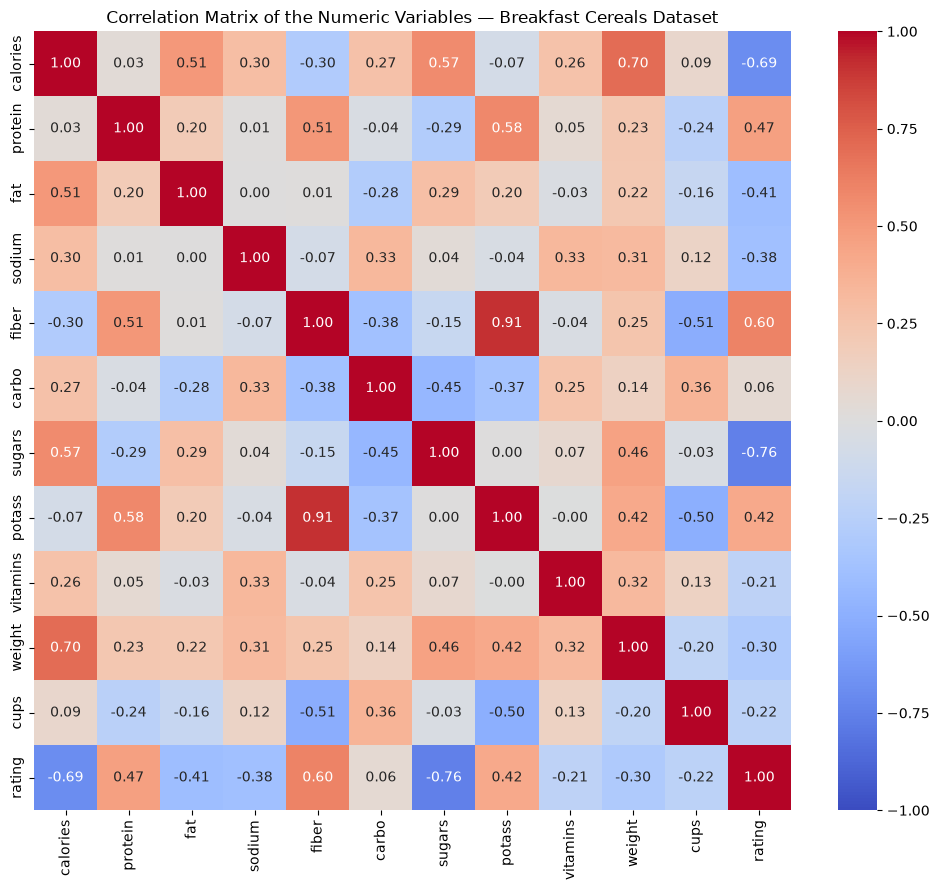

In [17]:
# Plot the correlations between all the numeric variables and the rating.
corr_matrix = num_vars.corr()

fig, ax = plt.subplots(figsize=(10, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    ax=ax
)

# Add a title that names the plot and the dataset.
ax.set_title("Correlation Matrix of the Numeric Variables — Breakfast Cereals Dataset")

plt.tight_layout()
plt.show()

In [18]:
# Count how many pairs of numeric predictors have a correlation of 0.5 or more in absolute value.
predictor_corr = num_vars.drop(columns="rating").corr()
rows, cols = np.triu_indices_from(predictor_corr, k=1)

predictor_pairs = pd.DataFrame({
    "Variable 1": predictor_corr.index[rows],
    "Variable 2": predictor_corr.columns[cols],
    "Correlation": predictor_corr.values[rows, cols]
})

strong_pairs = predictor_pairs[predictor_pairs["Correlation"].abs() >= 0.5]
strong_pairs = strong_pairs.sort_values("Correlation", key=abs, ascending=False)

print(f"Pairs with a correlation of 0.5 or more in absolute value: {len(strong_pairs)} of {len(predictor_pairs)}")
strong_pairs.round(2).reset_index(drop=True)

Pairs with a correlation of 0.5 or more in absolute value: 8 of 55


,Variable 1,Variable 2,Correlation
0,fiber,potass,0.91
1,calories,weight,0.70
2,protein,potass,0.58
3,calories,sugars,0.57
4,protein,fiber,0.51
5,fiber,cups,-0.51
6,calories,fat,0.51
7,potass,cups,-0.50


### Nutritional variable findings

The calories are similar across manufacturers, with a median of 110 for General Mills, Kelloggs, Post and Ralston Purina. Nabisco has the lowest median (90, from 5 cereals) and Quaker Oats the next lowest (100, from 7 cereals), while Ralston Purina has the highest mean (115.7). The groups are small, so these differences are only indicative.

The rating is negatively correlated with `sugars` (-0.756) and `calories` (-0.694), and positively correlated with `fiber` (0.603), `protein` (0.467) and `potass` (0.416). `fat` (-0.405) and `sodium` (-0.383) have a weaker negative correlation, and `carbo` has almost none (0.056). Cereals with more sugar and calories tend to have lower ratings, and cereals with more fiber, protein and potassium tend to have higher ratings. These are associations and not causes, since the calculation of the rating is unknown.

The numeric variables are only moderately correlated with each other. The strongest correlation is between `fiber` and `potass` (0.91), followed by `calories` and `weight` (0.70), and only a small share of the 55 pairs of predictors have a correlation of 0.5 or more in absolute value (they are listed in the table above). Therefore, PCA will remove part of the redundancy, but it will not reduce the 11 variables to a very small number of components.

## 11. Split into training and test sets

The data is divided into a training set and a test set before any step that learns from the data. The scaler, the PCA and the encoder of the next sections are fitted on the training set only and then applied to the test set. If they were fitted on all the cereals, information from the test set would leak into the training process and the evaluation of any future model would be too optimistic.

The exploration of sections 8 to 10 used all the cereals, because it only describes the data and no transformation was fitted on it. From this point on, every decision that depends on the data uses the training set only. With 74 cereals, 20% for testing leaves a test set of only 15, so the test set is small and any result measured on it will be noisy.

In [19]:
# Convert shelf to a categorical type, because it is a category coded with numbers and not a measurement.
df["shelf"] = df["shelf"].astype("category")

# Split the cleaned dataset into training and test sets with the fixed random seed.
train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

# Report the size of each set.
pd.DataFrame(
    {"Rows": [len(train_df), len(test_df)]},
    index=["Training set", "Test set"]
)

,Rows
Training set,59
Test set,15


In [20]:
# Separate the numeric predictors from the target in both sets.
numeric_vars = df.select_dtypes(include="number").drop(columns="rating").columns

X_train_num = train_df[numeric_vars].copy()
y_train = train_df["rating"].copy()

X_test_num = test_df[numeric_vars].copy()
y_test = test_df["rating"].copy()

### Split findings

The 74 cereals were divided into 59 for training and 15 for testing. The 11 numeric predictors are separated from the target `rating` in both sets, and the categorical variables stay in `train_df` and `test_df` until section 15.

## 12. Scale the numeric predictors and apply PCA

PCA looks for the directions in which the data varies the most. The numeric variables are measured in very different units: sodium and potassium are measured in milligrams and take values of dozens or hundreds, while the weight and the cups of a serving are fractions. If the variables were not scaled, the variables with the largest numbers would dominate the first components only because of their units. The table of standard deviations shows the difference, and the comparison table shows what PCA would do without scaling.

The variables are standardized, so each one has a mean of 0 and a standard deviation of 1, and PCA is then applied. Both the scaler and the PCA are fitted on the training set only and used to transform the test set. PCA is fitted with all 11 components first, so the variance of each one can be reviewed before choosing how many to keep.

In [21]:
# Compare the spread of the numeric predictors in the training set.
X_train_num.std().sort_values(ascending=False).round(2).to_frame(name="Standard deviation")

,Standard deviation
sodium,84.89
potass,70.92
vitamins,24.90
calories,21.40
sugars,4.31
carbo,3.84
fiber,2.42
protein,1.06
fat,1.03
cups,0.23


In [22]:
# Fit PCA without scaling to see what would happen if the variables kept their original units.
pca_without_scaling = PCA()
pca_without_scaling.fit(X_train_num)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [23]:
# Standardize the numeric predictors with the mean and standard deviation of the training set only.
scaler = StandardScaler()
scaler.fit(X_train_num)

X_train_scaled = scaler.transform(X_train_num)
X_test_scaled = scaler.transform(X_test_num)

# Fit PCA with all the components on the scaled training set and project both sets on them.
pca_with_scaling = PCA()
pca_with_scaling.fit(X_train_scaled)

X_train_scaled_projected = pca_with_scaling.transform(X_train_scaled)
X_test_scaled_projected = pca_with_scaling.transform(X_test_scaled)

total_components = X_train_scaled_projected.shape[1]

# Show the scores of the first training cereals on every component.
X_train_scaled_projected_df = pd.DataFrame(
    X_train_scaled_projected,
    columns=[f"PC{i + 1}" for i in range(total_components)],
    index=X_train_num.index
)

X_train_scaled_projected_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
22,-0.608412,0.508333,-1.818858,-0.618709,0.543877,-0.402256,0.350672,0.675753,0.087776,-0.444157,-0.209447
57,0.170530,-1.681576,-0.487524,-0.153953,-0.573309,-1.489059,-1.487936,-0.047430,-0.082644,0.283964,-0.068530
50,3.578765,0.785977,-0.197176,-1.372753,-0.371246,-0.577916,0.929357,-0.019130,-0.048470,0.352565,-0.028301
33,-0.744869,1.272633,-1.743035,-0.721976,0.191497,0.849017,0.378087,-0.437638,0.040331,-0.318918,0.145885
39,1.112050,-0.605205,-0.462729,0.890849,0.348801,0.881493,-0.404111,0.930074,0.389019,-0.072324,-0.182165


In [24]:
# Compare the first component with and without scaling: the variance it explains and its loading on sodium.
pca_comparison = pd.DataFrame({
    "Variance explained by PC1 (%)": [
        pca_without_scaling.explained_variance_ratio_[0] * 100,
        pca_with_scaling.explained_variance_ratio_[0] * 100
    ],
    "Loading of PC1 on sodium": [
        pca_without_scaling.components_[0][X_train_num.columns.get_loc("sodium")],
        pca_with_scaling.components_[0][X_train_num.columns.get_loc("sodium")]
    ]
}, index=["Without scaling", "With scaling"])

pca_comparison.round(3)

,Variance explained by PC1 (%),Loading of PC1 on sodium
Without scaling,55.574,0.973
With scaling,29.005,-0.042


### Scaling findings

In the training set, `sodium` has a standard deviation of 84.89 and `potass` of 70.92, against 0.23 for `cups` and 0.17 for `weight`. Without scaling, the first component would explain 55.57% of the variance with a loading of 0.97 on `sodium`, so it would be built almost only from the variables with the largest numbers and would reflect the units and not the nutritional profile of the cereals. After scaling, every variable has the same weight, the first component explains 29.01% of the variance and its loading on `sodium` is -0.04. The test set was transformed with the mean and the standard deviation of the training set.

## 13. Select the number of components

The variance explained by each component is reviewed with a table and two plots side by side: the eigenvalue of each component, with a line at 1 for the Kaiser criterion, and the cumulative percentage of variance, with a line at 90%. The number of components to keep is the minimum that explains more than 90% of the variance of the training set.

This criterion is a convention, not a result of the data, and other criteria give different numbers. The Kaiser criterion keeps the components with an eigenvalue above 1, which means that they explain more variance than one standardized variable. The 90% threshold is chosen because the purpose is to preserve the information of the nutritional variables for a later model, and not to visualize them in two or three dimensions. The table shows what each alternative would keep.

In [25]:
# Calculate the eigenvalue and the variance explained by each component. The cumulative variance is
# calculated from the unrounded values, so rounding errors do not accumulate.
eigenvalues = pca_with_scaling.explained_variance_
variance_explained = pca_with_scaling.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(variance_explained)

# Build a table indexed by component with the three measures.
pca_summary = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Variance explained (%)": variance_explained,
    "Cumulative variance (%)": cumulative_variance
}, index=range(1, total_components + 1))

pca_summary.round({"Eigenvalue": 3, "Variance explained (%)": 2, "Cumulative variance (%)": 2})

,Eigenvalue,Variance explained (%),Cumulative variance (%)
1,3.246,29.01,29.01
2,2.782,24.86,53.86
3,1.764,15.77,69.63
4,0.996,8.91,78.53
5,0.743,6.64,85.17
6,0.586,5.24,90.41
7,0.562,5.02,95.43
8,0.339,3.03,98.46
9,0.096,0.85,99.32
10,0.061,0.54,99.86


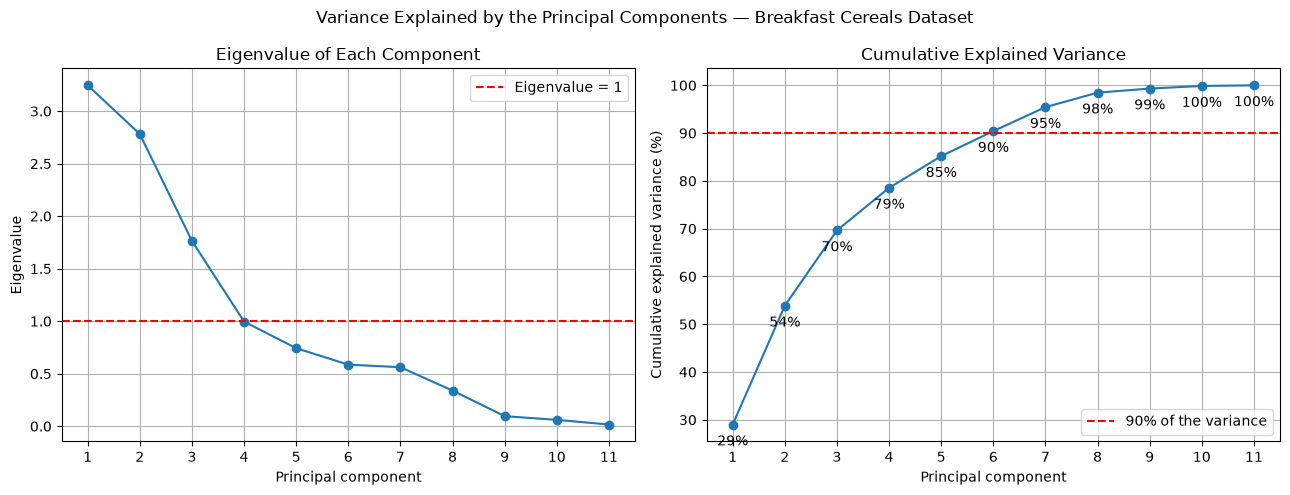

In [26]:
# Plot the eigenvalue and the cumulative variance of each component side by side.
components = pca_summary.index

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Eigenvalue of each component, with a red line at 1 for the Kaiser criterion.
axes[0].plot(components, pca_summary["Eigenvalue"], marker="o")
axes[0].axhline(1, color="red", linestyle="--", label="Eigenvalue = 1")
axes[0].set_title("Eigenvalue of Each Component")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Eigenvalue")
axes[0].set_xticks(components)
axes[0].legend()
axes[0].grid(True)

# Cumulative variance explained, with a red line at 90%.
axes[1].plot(components, pca_summary["Cumulative variance (%)"], marker="o")
axes[1].axhline(90, color="red", linestyle="--", label="90% of the variance")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Cumulative explained variance (%)")
axes[1].set_xticks(components)
axes[1].legend(loc="lower right")
axes[1].grid(True)

for component, value in zip(components, pca_summary["Cumulative variance (%)"]):
    axes[1].annotate(f"{value:.0f}%", (component, value), textcoords="offset points",
                     xytext=(0, -15), ha="center")

# Add a title for the whole figure and adjust spacing so it does not overlap the subplot titles.
fig.suptitle("Variance Explained by the Principal Components — Breakfast Cereals Dataset")
plt.tight_layout()
plt.show()

In [27]:
# Count the components needed to explain more than 90% of the variance: the components whose
# cumulative variance is still below 90%, plus the one that crosses it.
components_90 = int((cumulative_variance < 90).sum()) + 1
variance_90 = cumulative_variance[components_90 - 1]

# Count the components with an eigenvalue above 1 (Kaiser criterion).
components_kaiser = int((eigenvalues > 1).sum())
variance_kaiser = cumulative_variance[components_kaiser - 1]

# Compare what each criterion would keep.
components_summary = pd.DataFrame({
    "Criterion": ["Cumulative variance above 90%", "Eigenvalue above 1 (Kaiser)"],
    "Components kept": [components_90, components_kaiser],
    "Cumulative variance (%)": [variance_90, variance_kaiser]
})

components_summary.round({"Cumulative variance (%)": 2})

,Criterion,Components kept,Cumulative variance (%)
0,Cumulative variance above 90%,6,90.41
1,Eigenvalue above 1 (Kaiser),3,69.63


In [28]:
# Keep the first components that explain more than 90% of the variance, in both sets.
X_train_selected = X_train_scaled_projected[:, :components_90]
X_test_selected = X_test_scaled_projected[:, :components_90]

### Component selection findings

The first component explains 29.01% of the variance and the second 24.86%, and the cumulative variance reaches 69.63% with three components, 85.17% with five and 90.41% with six. Therefore, 6 components are the minimum that explains more than 90% of the variance, which reduces the 11 numeric variables to 6. The Kaiser criterion would keep only 3 components and 69.63% of the variance, which loses almost a third of the information, so it is not used. The fourth component has an eigenvalue of 0.996, just below the cutoff. The sixth component crosses the threshold by a narrow margin (90.41%), so a different split of the cereals could require a seventh. The test set was projected on the same 6 components, which were calculated from the training set only.

## 14. Interpret the principal components

Each component is a weighted combination of the 11 scaled variables, and the weights are called loadings. A loading close to 1 or -1 means that the variable contributes a lot to the component, and the sign shows the direction. The loadings of the selected components are shown with a heatmap, and the variables with the largest loadings in the first three components are listed: three for the first and second components, and five for the third, which contrasts two groups of variables.

The correlation of each component with the rating in the training set is shown as context for the modeling stage. It is not used to choose the components, which are selected only by the variance they explain, without looking at the target.

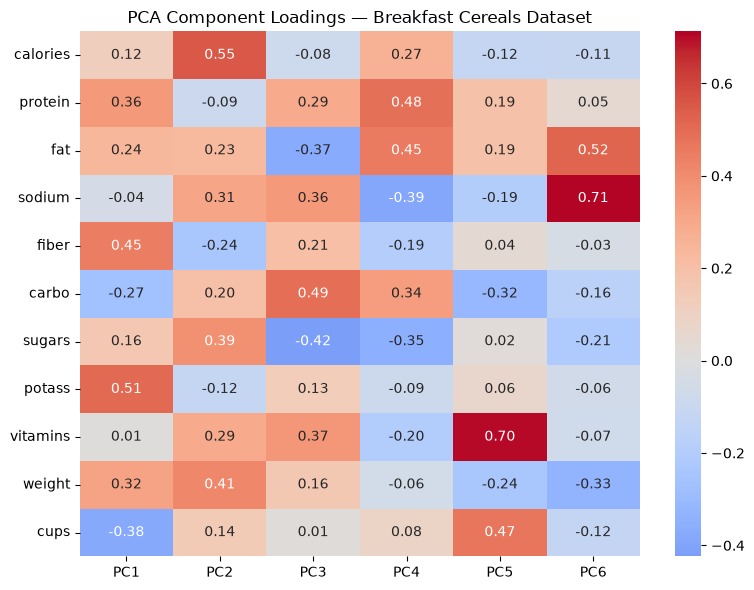

In [29]:
# Build a table with the loadings of the selected components (variables in rows, components in columns).
pca_components_loadings = pca_with_scaling.components_[:components_90, :].T
components_loadings_df = pd.DataFrame(
    data=pca_components_loadings,
    index=X_train_num.columns,
    columns=[f"PC{component}" for component in range(1, components_90 + 1)]
)

# Plot the signed loadings in an annotated heatmap.
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    data=components_loadings_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

# Add a title that names the plot and the dataset.
ax.set_title("PCA Component Loadings — Breakfast Cereals Dataset")

plt.tight_layout()
plt.show()

In [30]:
# List the three variables with the largest loadings (in absolute value) in the first component, keeping the sign.
pc1_largest_loadings_abs = components_loadings_df["PC1"].abs().nlargest(3)
components_loadings_df.loc[pc1_largest_loadings_abs.index, ["PC1"]]

,PC1
potass,0.510221
fiber,0.447274
cups,-0.375717


In [31]:
# List the three variables with the largest loadings (in absolute value) in the second component, keeping the sign.
pc2_largest_loadings_abs = components_loadings_df["PC2"].abs().nlargest(3)
components_loadings_df.loc[pc2_largest_loadings_abs.index, ["PC2"]]

,PC2
calories,0.550978
weight,0.414872
sugars,0.388193


In [32]:
# List the five variables with the largest loadings (in absolute value) in the third component, keeping the sign.
# Five are listed because this component contrasts two groups of variables.
pc3_largest_loadings_abs = components_loadings_df["PC3"].abs().nlargest(5)
components_loadings_df.loc[pc3_largest_loadings_abs.index, ["PC3"]]

,PC3
carbo,0.494186
sugars,-0.423787
fat,-0.370828
vitamins,0.365684
sodium,0.355180


In [33]:
# List the three training cereals with the highest score in the first component,
# with some of their nutritional values and their scores in PC1 and PC2.
top3_positions_pc1 = X_train_selected[:, 0].argsort()[::-1][:3]

top3_cereals_pc1 = train_df.iloc[top3_positions_pc1][["name", "calories", "sugars", "fiber", "weight"]].copy()
top3_cereals_pc1["PC1"] = X_train_selected[top3_positions_pc1, 0]
top3_cereals_pc1["PC2"] = X_train_selected[top3_positions_pc1, 1]
top3_cereals_pc1.round(2)

,name,calories,sugars,fiber,weight,PC1,PC2
3,All-Bran_with_Extra_Fiber,50,0.0,14.0,1.00,4.65,-4.84
2,All-Bran,70,5.0,9.0,1.00,4.48,-2.84
50,Post_Nat._Raisin_Bran,120,14.0,6.0,1.33,3.58,0.79


In [34]:
# List the three training cereals with the highest score in the second component,
# with the same columns as the previous table.
top3_positions_pc2 = X_train_selected[:, 1].argsort()[::-1][:3]

top3_cereals_pc2 = train_df.iloc[top3_positions_pc2][["name", "calories", "sugars", "fiber", "weight"]].copy()
top3_cereals_pc2["PC1"] = X_train_selected[top3_positions_pc2, 0]
top3_cereals_pc2["PC2"] = X_train_selected[top3_positions_pc2, 1]
top3_cereals_pc2.round(2)

,name,calories,sugars,fiber,weight,PC1,PC2
67,Total_Raisin_Bran,140,14.0,4.0,1.5,2.62,3.25
44,Mueslix_Crispy_Blend,160,13.0,3.0,1.5,2.65,2.97
37,Just_Right_Fruit_&_Nut,140,9.0,2.0,1.3,0.78,2.75


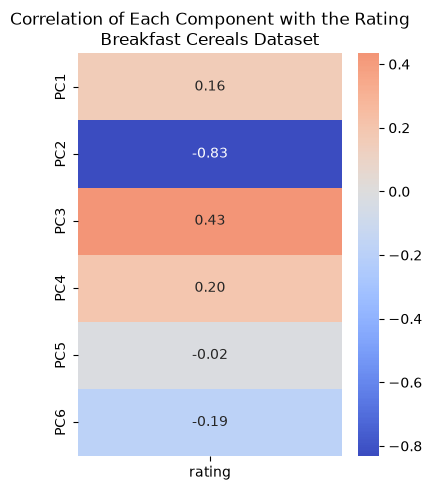

In [35]:
# Put the scores of the selected components in DataFrames, one for each set.
component_names = [f"PC{i}" for i in range(1, components_90 + 1)]

X_train_selected_df = pd.DataFrame(X_train_selected, columns=component_names)
X_test_selected_df = pd.DataFrame(X_test_selected, columns=component_names)

# Calculate the correlation of each selected component with the rating in the training set.
# The rating is converted to a Series with a consecutive index to align it with the component scores.
rating_correlations = X_train_selected_df.corrwith(pd.Series(y_train.values)).to_frame(name="rating")

# Plot the correlations in an annotated heatmap.
fig, ax = plt.subplots(figsize=(4, 5))

sns.heatmap(
    data=rating_correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

# Add a title that names the plot and the dataset.
ax.set_title("Correlation of Each Component with the Rating\nBreakfast Cereals Dataset")

plt.tight_layout()
plt.show()

### Component interpretation findings

The three variables with the largest loadings in the first component are `potass` (0.51), `fiber` (0.45) and `cups` (-0.38). `protein` (0.36) and `weight` (0.32) also contribute positively. A high value of the first component corresponds to cereals with a lot of potassium, fiber and protein and a small volume per serving. The three cereals with the highest score are All-Bran with Extra Fiber, All-Bran and Post Natural Raisin Bran, which are bran cereals.

The second component is built mainly from `calories` (0.55), `weight` (0.41) and `sugars` (0.39), with positive loadings on `sodium`, `vitamins` and `fat` too. A high value corresponds to energy-dense, sugary cereals with heavier servings. The three cereals with the highest score are Total Raisin Bran, Mueslix Crispy Blend and Just Right Fruit & Nut, which have 140 to 160 calories, 9 to 14 g of sugars and servings of 1.3 to 1.5 ounces. The third component contrasts `carbo` (0.49), `sodium` (0.36) and `vitamins` (0.37) with `sugars` (-0.42) and `fat` (-0.37).

The components that explain the most variance are not necessarily the most related to the rating. The second component has the strongest correlation with the rating (-0.83), which is consistent with the negative correlations of calories and sugars found in section 10. The third has a correlation of 0.43, the first of only 0.16, and the components from the fourth to the sixth are weaker (0.20, -0.02 and -0.19). Although the first component explains more variance, the second component has a much stronger relationship with the rating.

## 15. Select and encode the categorical predictors

The dataset has four categorical variables: `name`, `type`, `mfr` and `shelf`. Whether each one is a predictor is decided with evidence from the training set, and the ones kept are encoded.

The decision for each variable is:
- **`name`** identifies each cereal. If every cereal has a different name, there is no pattern to learn from it.
- **`type`** is only useful if it takes several values. If almost all the cereals have the same type, it carries no information.
- **`mfr`** is kept if the rating differs between manufacturers. It has no order (no manufacturer is above another), so it is a nominal variable.
- **`shelf`** is coded with the numbers 1, 2 and 3, and it is only treated as an ordered variable if the rating increases or decreases with the shelf. Otherwise it is nominal.

The nominal variables are encoded with one-hot encoding, which creates one binary column for each category and drops the first one to avoid redundant columns. This method is chosen because both variables have few categories (7 and 3), so the number of columns stays small. The encoder is fitted on the training set only.

In [36]:
# Check whether the cereal names are unique in the training set.
pd.DataFrame({
    "Unique names": [train_df["name"].nunique()],
    "Total rows": [train_df.shape[0]]
})

,Unique names,Total rows
0,59,59


In [37]:
# Count the cereals of each type in the training and in the test set.
pd.DataFrame({
    "Training set": train_df["type"].value_counts(),
    "Test set": test_df["type"].value_counts()
}).fillna(0).astype(int)

,Training set,Test set
type,,
C,58,15
H,1,0


In [38]:
# Calculate the mean rating of each manufacturer in the training set, with the number of cereals.
manufacturer_stats = train_df.groupby("mfr").agg(
    Mean_rating=("rating", "mean"),
    Number_of_cereals=("rating", "count")
)

manufacturer_stats

,Mean_rating,Number_of_cereals
mfr,,
A,54.850917,1
G,33.165515,16
K,45.724869,19
N,71.836874,3
P,40.961178,7
Q,45.742779,6
R,42.565591,7


In [39]:
# Calculate the mean rating and the mean sugars of each shelf in the training set, with the number of cereals.
shelf_stats = train_df.groupby("shelf", observed=True).agg(
    Mean_rating=("rating", "mean"),
    Mean_sugars=("sugars", "mean"),
    Number_of_cereals=("rating", "count")
)

shelf_stats

,Mean_rating,Mean_sugars,Number_of_cereals
shelf,,,
1,49.937512,3.615385,13
2,32.588357,9.600000,15
3,44.868173,6.580645,31


### Categorical predictor findings

- **`name`** has 59 different names in 59 training rows, so every cereal is unique and the variable is excluded.
- **`type`** has 58 cold cereals and 1 hot cereal in the training set, and the 15 test cereals are all cold. The variable has almost no variation, so it is excluded. This is a consequence of the removal of the hot cereals with missing values in section 7.
- **`mfr`** is a predictor. The mean rating changes a lot between manufacturers, from 33.2 for General Mills (16 cereals) to 45.7 for Kelloggs and Quaker Oats and 71.8 for Nabisco (3 cereals). Some groups are very small, so these means are uncertain. It is a nominal variable and it is one-hot encoded.
- **`shelf`** is a predictor, but it is not ordinal. The mean rating is 49.9 on shelf 1, 32.6 on shelf 2 and 44.9 on shelf 3, so it does not increase or decrease with the shelf: shelf 2 has the lowest rating and shelf 1 the highest. A rating that depended on the position from the floor would grow or fall steadily, so the numbers 1, 2 and 3 are not used as an ordered scale, and the variable is one-hot encoded. A correlation calculated with the codes 1, 2 and 3 would also miss this pattern, because it only detects steady increases or decreases. The shelf 2 cereals have more sugar (9.6 g, against 3.6 g on shelf 1 and 6.6 g on shelf 3), so part of the shelf effect probably reflects the sugar content, which is already described by the numeric variables.

Both predictors keep their first category as the reference, which is `A` for the manufacturer (a single cereal) and shelf 1 for the shelf.

In [40]:
# Select the categorical predictors kept for the model.
X_train_cat = train_df[["mfr", "shelf"]]
X_test_cat = test_df[["mfr", "shelf"]]

# Fit one-hot encoding on the training set only, dropping the first category of each variable
# and ignoring categories that were not seen in training.
onehot_encoder = OneHotEncoder(drop="first", handle_unknown="ignore")

X_train_onehot = onehot_encoder.fit_transform(X_train_cat)
X_test_onehot = onehot_encoder.transform(X_test_cat)

# Convert the encoded arrays into DataFrames with the feature names as columns and the original indexes.
X_train_encoded_df = pd.DataFrame(
    X_train_onehot.toarray(),
    columns=onehot_encoder.get_feature_names_out(),
    index=X_train_cat.index
)

X_test_encoded_df = pd.DataFrame(
    X_test_onehot.toarray(),
    columns=onehot_encoder.get_feature_names_out(),
    index=X_test_cat.index
)

X_train_encoded_df.head()

,mfr_G,mfr_K,mfr_N,mfr_P,mfr_Q,mfr_R,shelf_2,shelf_3
22,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
57,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
50,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
33,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
39,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


## 16. Build and save the final dataset

The selected principal components and the encoded categorical variables are combined into the final predictors of each set, and the target is kept as a separate column. Indexes are reset before concatenating, so the rows of the three parts stay aligned.

Before closing, a set of checks confirms that the datasets are ready: no missing values, the same columns in both sets, only numeric data and one target value for each row. The training and test sets are saved in `data/processed`, with the target `rating` as the last column of each file, so that a later modeling notebook can load them without repeating the preparation.

In [41]:
# Reset the indexes so the rows of the components, the encoded variables and the target stay aligned.
X_train_encoded_df = X_train_encoded_df.reset_index(drop=True)
X_test_encoded_df = X_test_encoded_df.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

# Concatenate the components and the encoded variables to build the final predictors of each set.
X_train_final = pd.concat([X_train_selected_df, X_train_encoded_df], axis=1)
X_test_final = pd.concat([X_test_selected_df, X_test_encoded_df], axis=1)

In [42]:
# Compare the size, missing values, non-numeric columns and target values of both final sets in one table.
final_sets_summary = pd.DataFrame({
    "Training set": [
        X_train_final.shape[0],
        X_train_final.shape[1],
        X_train_final.isna().sum().sum(),
        X_train_final.select_dtypes(exclude="number").shape[1],
        len(y_train)
    ],
    "Test set": [
        X_test_final.shape[0],
        X_test_final.shape[1],
        X_test_final.isna().sum().sum(),
        X_test_final.select_dtypes(exclude="number").shape[1],
        len(y_test)
    ]
}, index=[
    "Rows",
    "Columns",
    "Missing values",
    "Non-numeric columns",
    "Target values"
])

final_sets_summary

,Training set,Test set
Rows,59,15
Columns,14,14
Missing values,0,0
Non-numeric columns,0,0
Target values,59,15


In [43]:
# Check whether both sets have the same columns in the same order.
print("Both sets have the same columns:", X_train_final.columns.equals(X_test_final.columns))

Both sets have the same columns: True


In [44]:
# Preview the first rows of the final training set.
X_train_final.head()

,PC1,PC2,PC3,PC4,PC5,PC6,mfr_G,mfr_K,mfr_N,mfr_P,mfr_Q,mfr_R,shelf_2,shelf_3
0,-0.608412,0.508333,-1.818858,-0.618709,0.543877,-0.402256,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.170530,-1.681576,-0.487524,-0.153953,-0.573309,-1.489059,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,3.578765,0.785977,-0.197176,-1.372753,-0.371246,-0.577916,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.744869,1.272633,-1.743035,-0.721976,0.191497,0.849017,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,1.112050,-0.605205,-0.462729,0.890849,0.348801,0.881493,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [45]:
# Create the folder for the processed data and save both final sets, with the target as the last column.
processed_folder = Path("../data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

train_final = X_train_final.assign(rating=y_train)
test_final = X_test_final.assign(rating=y_test)

train_final.to_csv(processed_folder / "cereals_train.csv", index=False)
test_final.to_csv(processed_folder / "cereals_test.csv", index=False)

print(f"Saved {len(train_final)} training rows and {len(test_final)} test rows in {processed_folder}")

Saved 59 training rows and 15 test rows in ../data/processed


### Final dataset findings

The final predictors of each set are the 6 principal components, 6 columns for the manufacturer (7 categories minus the reference) and 2 for the shelf (3 categories minus the reference), which makes 14 columns. The checks confirm that the training set has 59 rows and the test set 15, that both have the same 14 columns, no missing values and no non-numeric columns, and that each row has one target value. Both sets are saved in `data/processed`.

## 17. Conclusions and next steps

### Key findings

- **Missing values:** four values were missing in three cereals. They were removed (3.9% of the rows), and two of them were hot cereals, which leaves 73 cold cereals and 1 hot cereal.
- **Rating:** the rating is negatively correlated with `sugars` (-0.756) and `calories` (-0.694) and positively with `fiber` (0.603), `protein` (0.467) and `potass` (0.416). All 5 Nabisco cereals are among the 10 best rated.
- **Relationships between variables:** the numeric variables are only moderately correlated (the strongest pair is `fiber` and `potass`, 0.91), so PCA removes some redundancy but does not reduce the data to a very small number of components.
- **PCA:** after scaling, 6 components explain 90.41% of the variance of the training set, which reduces the 11 numeric variables to 6. The first component reflects potassium, fiber and protein (bran-like cereals), and the second reflects calories, serving weight and sugars. The second component has the strongest correlation with the rating (-0.83).
- **Categorical predictors:** `name` and `type` were excluded, `mfr` was kept as a nominal variable, and `shelf` was kept as a nominal and not an ordinal variable, because the rating is lowest on the middle shelf and similar on the other two.
- **Final dataset:** the training set has 59 cereals and the test set 15. Both have the same 14 numeric predictors (6 principal components, 6 manufacturer columns, and 2 shelf columns), no missing values, and `rating` as the target, saved as the last column of each file.

### Data-quality issues and limitations

- **Small sample:** with 59 training cereals and 15 test cereals, the loadings, the number of components and any future error measured on the test set are sensitive to the split. The sixth component crosses the 90% threshold by a narrow margin.
- **Mostly cold cereals:** 73 of the 74 cereals are cold, so the findings do not describe hot cereals.
- **Unknown rating:** the calculation of the rating is not documented, so the associations found describe the data and are not explanations.
- **Exploration on all cereals:** sections 8 to 10 used all 74 cereals, including the test cereals. No transformation was fitted on them, and the decisions about the categorical predictors use the training set only.
- **Small groups:** manufacturers `A` and `N` have 1 and 3 training cereals, so their mean ratings are very uncertain, and `A` is the reference category of the manufacturer encoding.
- **Shelf and sugar:** the lower rating on shelf 2 probably overlaps with the higher sugar content of those cereals, so `shelf` may add little to the numeric variables.

### Next steps

- Train a regression model on the training set and evaluate it on the test set with error metrics, using cross-validation because the sample is small.
- Compare the model with the principal components against a model with the original scaled variables, to measure whether the reduction helps.
- Compare the model with and without `shelf` to measure its contribution.
- Repeat the selection of components with other splits to check how stable the number of components and the loadings are.
- Save the fitted scaler, PCA and encoder so that new cereals can be transformed in the same way before they are given to the model.

### Final note

This notebook prepares the data for modeling for portfolio purposes. It does not train a model, and it makes no claim about predictive performance. Its decisions are limited to the supplied dataset.